# Section 4.4 — Feature Importance and Interpretation

## 1. Purpose and scope

This visualization-only notebook creates three publication figures from the three approved Section 4.4 CSV files. It does not load models, retrain, preprocess, recompute importance or SHAP, or modify approved source data.

**Chart contract.** The final surface is a one-column LaTeX report. Figure 4.4-A is an annotated within-method rank heatmap (maximum 12 features); Figure 4.4-B is a signed diverging horizontal bar chart (five coefficients per direction); Figure 4.4-C is a ranked horizontal bar chart (top ten mean absolute SHAP values). All use a white background, DejaVu Sans, restrained colorblind-friendly colors, deterministic ordering, 7-inch nominal width, vector PDF, and 450-DPI PNG. The final QA surface is the exported PNG opened and displayed below at normal report width.

## 2. Imports and publication style

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import textwrap

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from PIL import Image
from IPython.display import display

mpl.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 8.5,
    'axes.labelsize': 9.5,
    'xtick.labelsize': 8.2,
    'ytick.labelsize': 8.4,
    'axes.edgecolor': '#4A4A4A',
    'axes.linewidth': 0.7,
    'text.color': '#222222',
    'axes.labelcolor': '#222222',
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})
PNG_DPI = 450

def format_plot_feature_label(label: str) -> str:
    """Apply the report-only categorical separator without changing source labels."""
    return str(label).replace(' = ', ': ')

def wrap_plot_feature_label(label: str, max_chars: int = 31) -> str:
    """Wrap only genuinely long categorical labels, never beyond two lines."""
    label = str(label)
    if len(label) <= max_chars:
        return label
    if ': ' in label:
        left, right = label.split(': ', 1)
        return f'{left}:\n{right}'
    return textwrap.fill(label, width=max_chars, max_lines=2, placeholder='…')

def file_sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

def file_evidence(path: Path) -> dict:
    """Return auditable disk evidence for an exact resolved export path."""
    path = path.resolve()
    stat = path.stat()
    evidence = {
        'path': str(path),
        'size_bytes': stat.st_size,
        'modified_at': datetime.fromtimestamp(stat.st_mtime).astimezone().isoformat(timespec='seconds'),
        'sha256': file_sha256(path),
    }
    if path.suffix.lower() == '.png':
        with Image.open(path) as image_file:
            image_file.load()
            evidence['pixel_dimensions'] = tuple(image_file.size)
    return evidence
print(f'Publication style configured; PNG export DPI = {PNG_DPI}.')

Publication style configured; PNG export DPI = 450.


## 3. Path and source configuration

In [ ]:
cwd = Path.cwd().resolve()
if (cwd / 'reports' / 'data_reports').is_dir() and cwd.name == 'Source':
    PROJECT_ROOT = cwd
elif (cwd / 'Source' / 'reports' / 'data_reports').is_dir():
    PROJECT_ROOT = cwd / 'Source'
else:
    candidates = [p for p in [cwd, *cwd.parents] if (p / 'Source' / 'reports' / 'data_reports').is_dir()]
    assert candidates, 'Could not locate Source from the current working directory.'
    PROJECT_ROOT = candidates[0] / 'Source'

PROJECT_ROOT = PROJECT_ROOT.resolve()
NOTEBOOK_PATH = (PROJECT_ROOT / 'notebooks' / '10_section_4_4_visualizations.ipynb').resolve()
DATA_DIR = (PROJECT_ROOT / 'reports' / 'data_reports').resolve()
FIGURE_DIR = (PROJECT_ROOT / 'reports' / 'figures').resolve()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SOURCES = {
    'cross': DATA_DIR / 'powerbi_cross_model_feature_rank.csv',
    'logistic': DATA_DIR / 'powerbi_logistic_signed_coefficients.csv',
    'shap': DATA_DIR / 'powerbi_xgboost_shap_global.csv',
}
assert all(path.is_file() for path in SOURCES.values()), SOURCES
source_hashes_before = {key: file_sha256(path) for key, path in SOURCES.items()}
print('Resolved notebook:', NOTEBOOK_PATH)
print('Resolved project root:', PROJECT_ROOT)
for key, path in SOURCES.items():
    print(f'Approved source [{key}]: {path}')

Resolved notebook: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\notebooks\10_section_4_4_visualizations.ipynb
Resolved project root: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2
Approved source [cross]: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\powerbi_cross_model_feature_rank.csv
Approved source [logistic]: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\powerbi_logistic_signed_coefficients.csv
Approved source [shap]: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\powerbi_xgboost_shap_global.csv


## 4. Load and validate approved CSVs

In [ ]:
cross = pd.read_csv(SOURCES['cross'])
logistic = pd.read_csv(SOURCES['logistic'])
shap = pd.read_csv(SOURCES['shap'])

cross_columns = ['Model', 'Method', 'Method_Order', 'Feature_Code', 'Feature_Display_Name', 'Driver_Group', 'Rank', 'Raw_Importance', 'Importance_Unit', 'Top_10_Flag']
logistic_columns = ['Feature_Code', 'Feature_Display_Name', 'Base_Feature', 'Base_Feature_Display_Name', 'Encoded_Category', 'Encoded_Category_Display_Name', 'Coefficient', 'Abs_Coefficient', 'Direction', 'Absolute_Rank', 'Sign_Rank', 'Reference_Category']
shap_columns = ['Model', 'Feature_Code', 'Feature_Display_Name', 'Driver_Group', 'Mean_Abs_SHAP', 'Rank', 'Explained_Class', 'Dataset', 'Sample_Size', 'Predictor_Count', 'SHAP_Output_Scale', 'Explainer_Type', 'Additivity_Check_Passed', 'Max_Additivity_Error', 'Additivity_Tolerance']
assert list(cross.columns) == cross_columns and cross.shape == (60, 10)
assert list(logistic.columns) == logistic_columns and logistic.shape == (26, 12)
assert list(shap.columns) == shap_columns and shap.shape == (18, 15)

expected_methods = [
    'Logistic Regression coefficients',
    'Random Forest impurity importance',
    'XGBoost gain importance',
    'LightGBM gain importance',
    'CatBoost FeatureImportance',
    'XGBoost SHAP mean absolute impact',
]
ordered_methods = (cross[['Method_Order', 'Method']].drop_duplicates().sort_values('Method_Order')['Method'].tolist())
assert ordered_methods == expected_methods
assert cross['Method'].nunique() == 6 and cross.groupby('Method').size().eq(10).all()
assert not cross.duplicated(['Method', 'Feature_Code']).any()
assert not cross[['Method', 'Feature_Code', 'Rank']].isna().any().any()
assert pd.api.types.is_integer_dtype(cross['Rank'])
assert cross.groupby('Method')['Rank'].apply(lambda s: sorted(s.tolist()) == list(range(1, 11))).all()
assert pd.api.types.is_numeric_dtype(cross['Raw_Importance'])

assert logistic['Feature_Code'].nunique() == 26 and not logistic['Feature_Code'].duplicated().any()
assert logistic['Direction'].value_counts().to_dict() == {'Negative': 15, 'Positive': 11}
assert (logistic['Coefficient'] != 0).all() and pd.api.types.is_numeric_dtype(logistic['Coefficient'])
assert np.allclose(logistic['Abs_Coefficient'], logistic['Coefficient'].abs(), rtol=0, atol=1e-12)
assert ((logistic['Coefficient'] > 0) == logistic['Direction'].eq('Positive')).all()
assert logistic.groupby('Direction')['Sign_Rank'].apply(lambda s: sorted(s.tolist()) == list(range(1, len(s) + 1))).all()

assert shap['Feature_Code'].nunique() == 18 and not shap['Feature_Code'].duplicated().any()
assert not shap[shap_columns].isna().any().any() and (shap['Mean_Abs_SHAP'] >= 0).all()
assert sorted(shap['Rank'].tolist()) == list(range(1, 19))
assert shap.sort_values('Mean_Abs_SHAP', ascending=False)['Rank'].tolist() == list(range(1, 19))
assert shap['Model'].eq('XGBoost').all() and shap['Explained_Class'].eq('Churn = 1').all()
assert shap['Dataset'].eq('Validation').all() and shap['Sample_Size'].eq(500).all()
assert shap['Predictor_Count'].eq(18).all() and shap['Explainer_Type'].eq('Native TreeSHAP').all()
assert shap['Additivity_Check_Passed'].eq(True).all()
assert (shap['Max_Additivity_Error'] < shap['Additivity_Tolerance']).all()
print('PASS: source schemas, row counts, keys, ranks, signs, and SHAP metadata are valid.')

PASS: source schemas, row counts, keys, ranks, signs, and SHAP metadata are valid.


## 5. Canonical mapping assertions

In [ ]:
canonical = {
    'Tenure': ('Tenure (Months)', 'Tenure'),
    'tenure_group': ('Tenure Group', 'Tenure'),
    'Contract': ('Contract Type', 'Contract Type'),
}
for source_name, frame in {'cross': cross, 'logistic': logistic, 'shap': shap}.items():
    for feature_code, (display_name, driver_group) in canonical.items():
        rows = frame.loc[frame['Feature_Code'].eq(feature_code)]
        if rows.empty:
            continue
        assert rows['Feature_Display_Name'].eq(display_name).all(), f'{source_name}: stale display for {feature_code}'
        if 'Driver_Group' in rows.columns:
            assert rows['Driver_Group'].eq(driver_group).all(), f'{source_name}: invalid driver group for {feature_code}'
assert {'Tenure', 'tenure_group'}.issubset(set(cross['Feature_Code']))
assert {'Tenure', 'tenure_group'}.issubset(set(shap['Feature_Code']))
assert logistic.loc[logistic['Feature_Code'].eq('Tenure'), 'Feature_Display_Name'].eq('Tenure (Months)').all()
print('PASS: canonical Tenure, tenure_group, and Contract mappings are valid; feature identities remain separate.')

PASS: canonical Tenure, tenure_group, and Contract mappings are valid; feature identities remain separate.


## 6. Cross-model matrix preparation

In [ ]:
cross_stats = (
    cross.groupby(['Feature_Code', 'Feature_Display_Name'], as_index=False)
    .agg(Method_Count=('Method', 'nunique'), Mean_Rank=('Rank', 'mean'), Min_Rank=('Rank', 'min'))
    .sort_values(['Method_Count', 'Mean_Rank', 'Min_Rank', 'Feature_Display_Name'], ascending=[False, True, True, True], kind='mergesort')
)
cross_selected = cross_stats.loc[cross_stats['Method_Count'].ge(2)].head(12).copy()
assert len(cross_selected) == 12 and cross_selected['Method_Count'].ge(2).all()
assert {'Tenure', 'tenure_group'}.issubset(set(cross_selected['Feature_Code']))
selected_codes = cross_selected['Feature_Code'].tolist()
selected_labels = cross_selected['Feature_Display_Name'].tolist()
matrix = (cross.loc[cross['Feature_Code'].isin(selected_codes)]
          .pivot(index='Feature_Display_Name', columns='Method', values='Rank')
          .reindex(index=selected_labels, columns=expected_methods))
assert matrix.shape == (12, 6)
for display_name in matrix.index:
    for method in matrix.columns:
        source_value = cross.loc[cross['Feature_Display_Name'].eq(display_name) & cross['Method'].eq(method), 'Rank']
        plotted_value = matrix.loc[display_name, method]
        assert (source_value.empty and pd.isna(plotted_value)) or (len(source_value) == 1 and plotted_value == source_value.iloc[0])
print('PASS: selected 12 features deterministically and reconciled every matrix cell to source ranks.')
display(cross_selected)

PASS: selected 12 features deterministically and reconciled every matrix cell to source ranks.


,Feature_Code,Feature_Display_Name,Method_Count,Mean_Rank,Min_Rank
15,Tenure,Tenure (Months),6,4.833333,3
8,MonthlyCharges,Monthly Charges,6,5.000000,2
0,Contract,Contract Type,5,2.000000,1
16,TotalCharges,Total Charges,5,2.800000,1
3,Dependents,Dependents,5,3.400000,1
17,monthly_charges_ratio,Monthly Charges Ratio,4,5.000000,2
5,InternetService,Internet Service,4,7.000000,3
13,PaymentMethod,Payment Method,4,7.000000,6
18,service_diversity,Service Diversity Score,4,9.250000,8
19,tenure_group,Tenure Group,3,6.666667,4


## 7. Cross-model matrix generation

In [ ]:
figure_specs = {}
matrix_pdf = FIGURE_DIR / 'section_4_4_01_cross_model_feature_rank_matrix.pdf'
matrix_png = FIGURE_DIR / 'section_4_4_01_cross_model_feature_rank_matrix.png'
assert matrix_pdf.is_file() and matrix_png.is_file(), 'Figure 4.4-A must already exist and is not regenerated in this adjustment.'
driver_convergence_candidates = [
    FIGURE_DIR / 'section_4_4_01_cross_model_driver_convergence.pdf',
    FIGURE_DIR / 'section_4_4_01_cross_model_driver_convergence.png',
]
figure_a_protected_paths = [matrix_pdf, matrix_png] + [path for path in driver_convergence_candidates if path.exists()]
figure_a_hash_before = {path.name: file_sha256(path) for path in figure_a_protected_paths}
rank_colors = ['#173B63', '#24517B', '#34658F', '#4D79A1', '#6B8FB3', '#89A6C3', '#A9BED2', '#C7D5E2', '#E0E7EE', '#F0F3F6']
rank_cmap = ListedColormap(rank_colors)
rank_cmap.set_bad('white')
rank_norm = BoundaryNorm(np.arange(0.5, 11.5, 1), rank_cmap.N)
method_labels = ['Logistic\nRegression', 'Random\nForest', 'XGBoost\nGain', 'LightGBM\nGain', 'CatBoost\nImportance', 'XGBoost\nSHAP']
fig, ax = plt.subplots(figsize=(7.0, 5.55))
image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy(dtype=float)), cmap=rank_cmap, norm=rank_norm, aspect='auto')
ax.set_xticks(np.arange(6), labels=method_labels)
ax.set_yticks(np.arange(12), labels=matrix.index.tolist())
ax.set_xlabel('Importance method', labelpad=8)
ax.set_ylabel('Feature')
ax.tick_params(axis='x', length=0, pad=6, labelsize=8.0)
ax.tick_params(axis='y', length=0, pad=5)
ax.set_xticks(np.arange(-0.5, 6, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 12, 1), minor=True)
ax.grid(which='minor', color='#D9D9D9', linewidth=0.65)
ax.tick_params(which='minor', bottom=False, left=False)
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        value = matrix.iat[row_index, column_index]
        if pd.notna(value):
            ax.text(column_index, row_index, f'{int(value)}', ha='center', va='center', fontsize=8.0, fontweight='semibold', color='white' if value <= 4 else '#202020')
colorbar = fig.colorbar(image, ax=ax, fraction=0.036, pad=0.025, ticks=[1, 10])
colorbar.set_label('Within-method rank', fontsize=9.0, labelpad=7)
colorbar.ax.set_yticklabels(['1  strongest', '10  lower top-ten'], fontsize=7.7)
colorbar.outline.set_linewidth(0.5)
fig.text(0.105, 0.017, 'Lower ranks indicate greater within-method importance; raw importance magnitudes are not comparable across methods.', fontsize=7.6, color='#444444')
fig.subplots_adjust(left=0.255, right=0.91, top=0.985, bottom=0.175)
# Figure 4.4-A is intentionally not saved or regenerated in this presentation adjustment.
plt.close(fig)
figure_specs['4.4-A'] = {'name': 'Cross-model feature-rank matrix', 'source': SOURCES['cross'], 'pdf': matrix_pdf, 'png': matrix_png, 'width': 7.0, 'height': 5.55, 'rows': 12}
print('Preserved byte-for-byte:', matrix_pdf)
print('Preserved byte-for-byte:', matrix_png)

Preserved byte-for-byte: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_01_cross_model_feature_rank_matrix.pdf
Preserved byte-for-byte: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_01_cross_model_feature_rank_matrix.png


## 8. Logistic coefficient preparation

In [ ]:
logistic_display_names_before = logistic['Feature_Display_Name'].copy(deep=True)
logistic_selected = logistic.loc[logistic['Sign_Rank'].le(5)].copy()
logistic_selected['Plot_Feature_Label'] = (logistic_selected['Feature_Display_Name']
                                                   .map(format_plot_feature_label)
                                                   .map(wrap_plot_feature_label))
normalized_plot_labels = logistic_selected['Plot_Feature_Label'].str.replace('\n', ' ', regex=False)
expected_plot_labels = logistic_selected['Feature_Display_Name'].str.replace(' = ', ': ', regex=False)
assert normalized_plot_labels.eq(expected_plot_labels).all()
assert logistic['Feature_Display_Name'].str.contains(' = ', regex=False).any(), 'Source labels must remain unchanged.'
positive = logistic_selected.loc[logistic_selected['Direction'].eq('Positive')].sort_values(['Abs_Coefficient', 'Feature_Display_Name'], ascending=[False, True], kind='mergesort')
negative = logistic_selected.loc[logistic_selected['Direction'].eq('Negative')].sort_values(['Abs_Coefficient', 'Feature_Display_Name'], ascending=[False, True], kind='mergesort')
assert len(positive) == 5 and len(negative) == 5 and len(logistic_selected) == 10
assert positive['Sign_Rank'].tolist() == list(range(1, 6)) and negative['Sign_Rank'].tolist() == list(range(1, 6))
logistic_plot = pd.concat([positive, negative], ignore_index=True)
assert np.array_equal(logistic_plot['Coefficient'].to_numpy(), pd.concat([positive, negative])['Coefficient'].to_numpy())
logistic_invariance_columns = ['Feature_Code', 'Coefficient', 'Direction', 'Sign_Rank']
logistic_expected = pd.concat([positive, negative], ignore_index=True)[logistic_invariance_columns]
assert logistic_plot[logistic_invariance_columns].equals(logistic_expected)
assert not logistic_plot['Plot_Feature_Label'].str.contains(' = ', regex=False).any()
assert logistic['Feature_Display_Name'].equals(logistic_display_names_before)
print('PASS: selected exactly five positive and five negative coefficients by Sign_Rank <= 5.')
display(logistic_plot[['Feature_Code', 'Feature_Display_Name', 'Plot_Feature_Label', 'Coefficient', 'Direction', 'Sign_Rank']])

PASS: selected exactly five positive and five negative coefficients by Sign_Rank <= 5.


,Feature_Code,Feature_Display_Name,Plot_Feature_Label,Coefficient,Direction,Sign_Rank
0,MonthlyCharges,Monthly Charges,Monthly Charges,0.334798,Positive,1
1,monthly_charges_ratio,Monthly Charges Ratio,Monthly Charges Ratio,0.334798,Positive,2
2,PaperlessBilling_1,Paperless Billing = Yes,Paperless Billing: Yes,0.236857,Positive,3
3,InternetService_Fiber optic,Internet Service = Fiber optic,Internet Service: Fiber optic,0.159882,Positive,4
4,Partner_1,Partner = Yes,Partner: Yes,0.125992,Positive,5
5,TotalCharges,Total Charges,Total Charges,-0.766378,Negative,1
6,Contract_24,Contract Type = Two year,Contract Type: Two year,-0.683150,Negative,2
7,Dependents_Yes,Dependents = Yes,Dependents: Yes,-0.649922,Negative,3
8,InternetService_No,Internet Service = No Internet Service,Internet Service:\nNo Internet Service,-0.378273,Negative,4
9,Contract_12,Contract Type = One year,Contract Type: One year,-0.336179,Negative,5


## 9. Logistic coefficient figure generation

In [ ]:
logistic_pdf = (FIGURE_DIR / 'section_4_4_02_logistic_signed_coefficients.pdf').resolve()
logistic_png = (FIGURE_DIR / 'section_4_4_02_logistic_signed_coefficients.png').resolve()
print('Figure 4.4-B PDF target:', logistic_pdf)
print('Figure 4.4-B PNG target:', logistic_png)
logistic_export_before = {'pdf': file_evidence(logistic_pdf), 'png': file_evidence(logistic_png)}
print('Figure 4.4-B pre-save evidence:', logistic_export_before)
bar_figure_style = {
    'font.family': 'DejaVu Sans', 'font.size': 9.0, 'axes.labelsize': 9.6,
    'xtick.labelsize': 8.8, 'ytick.labelsize': 9.2, 'axes.linewidth': 0.65,
    'axes.edgecolor': '#454545', 'text.color': '#222222',
    'axes.labelcolor': '#222222', 'xtick.color': '#333333', 'ytick.color': '#222222',
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
}
y_positions = np.array([0, 1, 2, 3, 4, 5.4, 6.4, 7.4, 8.4, 9.4], dtype=float)
bar_colors = np.where(logistic_plot['Direction'].eq('Positive'), '#4E79A7', '#C97943')
axis_limit = 0.95
with mpl.rc_context(bar_figure_style):
    fig, ax = plt.subplots(figsize=(7.0, 4.70))
    ax.barh(y_positions, logistic_plot['Coefficient'], color=bar_colors, edgecolor='none', height=0.64, zorder=2)
    ax.set_yticks(y_positions, labels=logistic_plot['Plot_Feature_Label'])
    ax.set_ylim(9.92, -0.52)
    ax.set_xlim(-axis_limit, axis_limit)
    ax.set_xticks(np.arange(-0.8, 0.81, 0.2))
    ax.axvline(0, color='#353535', linewidth=0.80, zorder=3)
    ax.set_xlabel('Standardized logistic coefficient', labelpad=6)
    ax.grid(axis='x', color='#E4E4E4', linewidth=0.55, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_linewidth(0.65)
    ax.tick_params(axis='y', length=0, pad=5)
    ax.tick_params(axis='x', width=0.65, length=3.5, pad=4)
    for y, value in zip(y_positions, logistic_plot['Coefficient']):
        offset = 0.018 if value > 0 else -0.018
        ax.text(value + offset, y, f'{value:+.3f}', va='center',
                ha='left' if value > 0 else 'right', fontsize=8.5, color='#303030', zorder=4)
    assert not any(' = ' in tick.get_text() for tick in ax.get_yticklabels())
    assert ax.get_ylabel() == ''
    assert len(fig.texts) == 0, 'Figure 4.4-B must not contain a figure-level footer.'
    fig.subplots_adjust(left=0.30, right=0.985, top=0.985, bottom=0.135)
    fig.savefig(logistic_pdf, bbox_inches='tight', facecolor='white', pad_inches=0.025)
    fig.savefig(logistic_png, dpi=PNG_DPI, bbox_inches='tight', facecolor='white', pad_inches=0.025)
    plt.close(fig)
logistic_export_after = {'pdf': file_evidence(logistic_pdf), 'png': file_evidence(logistic_png)}
assert logistic_export_after['pdf']['sha256'] != logistic_export_before['pdf']['sha256']
assert logistic_export_after['png']['sha256'] != logistic_export_before['png']['sha256']
print('Figure 4.4-B post-save evidence:', logistic_export_after)
figure_specs['4.4-B'] = {'name': 'Logistic signed coefficients', 'source': SOURCES['logistic'], 'pdf': logistic_pdf, 'png': logistic_png, 'width': 7.0, 'height': 4.70, 'rows': 10}
print('Created:', logistic_pdf)
print('Created:', logistic_png)

Figure 4.4-B PDF target: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_02_logistic_signed_coefficients.pdf
Figure 4.4-B PNG target: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_02_logistic_signed_coefficients.png
Figure 4.4-B pre-save evidence: {'pdf': {'path': 'D:\\FPTU_Study\\SU2026\\ADY201m\\Project_ADY201m_GR01_AI2009_H1\\churn_pipeline_v2\\reports\\figures\\section_4_4_02_logistic_signed_coefficients.pdf', 'size_bytes': 15270, 'modified_at': '2026-07-13T22:14:56+07:00', 'sha256': 'e239b74883566406d4817fa6067f1b7c825a63fa4763a885eed29aedf32bcc03'}, 'png': {'path': 'D:\\FPTU_Study\\SU2026\\ADY201m\\Project_ADY201m_GR01_AI2009_H1\\churn_pipeline_v2\\reports\\figures\\section_4_4_02_logistic_signed_coefficients.png', 'size_bytes': 257931, 'modified_at': '2026-07-13T22:14:56+07:00', 'sha256': '6f118a63b9021807111b440b86ee8bbf1f5b348a72550a8de01d22f8e90465d5', 'pixel_

Figure 4.4-B post-save evidence: {'pdf': {'path': 'D:\\FPTU_Study\\SU2026\\ADY201m\\Project_ADY201m_GR01_AI2009_H1\\churn_pipeline_v2\\reports\\figures\\section_4_4_02_logistic_signed_coefficients.pdf', 'size_bytes': 14731, 'modified_at': '2026-07-13T22:21:17+07:00', 'sha256': '49f46795c204063f44d5fda097f11ee6c8e0ec1a847256335054bf7f69ce0544'}, 'png': {'path': 'D:\\FPTU_Study\\SU2026\\ADY201m\\Project_ADY201m_GR01_AI2009_H1\\churn_pipeline_v2\\reports\\figures\\section_4_4_02_logistic_signed_coefficients.png', 'size_bytes': 245721, 'modified_at': '2026-07-13T22:21:17+07:00', 'sha256': '1b1c38ced9457c0751655460aea2092808840a0684a877c7b7769332a2f8a203', 'pixel_dimensions': (3008, 2017)}}
Created: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_02_logistic_signed_coefficients.pdf
Created: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_02_logistic_signed_coefficients.png


## 10. SHAP preparation

In [ ]:
shap_display_names_before = shap['Feature_Display_Name'].copy(deep=True)
shap_selected = shap.loc[shap['Rank'].le(10)].sort_values(['Rank', 'Feature_Display_Name'], kind='mergesort').copy()
shap_selected['Plot_Feature_Label'] = shap_selected['Feature_Display_Name'].map(format_plot_feature_label)
assert shap_selected['Plot_Feature_Label'].eq(shap_selected['Feature_Display_Name'].str.replace(' = ', ': ', regex=False)).all()
assert len(shap_selected) == 10 and shap_selected['Rank'].tolist() == list(range(1, 11))
assert shap_selected['Mean_Abs_SHAP'].is_monotonic_decreasing
assert shap_selected.iloc[0]['Mean_Abs_SHAP'] == shap['Mean_Abs_SHAP'].max()
source_top_ten = shap.sort_values('Rank').head(10)[['Feature_Code', 'Mean_Abs_SHAP', 'Rank']].reset_index(drop=True)
assert shap_selected[['Feature_Code', 'Mean_Abs_SHAP', 'Rank']].reset_index(drop=True).equals(source_top_ten)
assert not shap_selected['Plot_Feature_Label'].str.contains(' = ', regex=False).any()
assert shap['Feature_Display_Name'].equals(shap_display_names_before)
print('PASS: selected and reconciled the ten highest-ranked mean absolute SHAP values.')
display(shap_selected[['Feature_Code', 'Feature_Display_Name', 'Plot_Feature_Label', 'Mean_Abs_SHAP', 'Rank']])

PASS: selected and reconciled the ten highest-ranked mean absolute SHAP values.


,Feature_Code,Feature_Display_Name,Plot_Feature_Label,Mean_Abs_SHAP,Rank
0,Contract,Contract Type,Contract Type,0.868689,1
1,Dependents,Dependents,Dependents,0.618558,2
2,Tenure,Tenure (Months),Tenure (Months),0.559808,3
3,MonthlyCharges,Monthly Charges,Monthly Charges,0.471737,4
4,TotalCharges,Total Charges,Total Charges,0.225720,5
5,PaperlessBilling,Paperless Billing,Paperless Billing,0.178977,6
6,PaymentMethod,Payment Method,Payment Method,0.172323,7
7,InternetService,Internet Service,Internet Service,0.160645,8
8,Partner,Partner,Partner,0.106579,9
9,TechSupport,Tech Support,Tech Support,0.096741,10


## 11. SHAP figure generation

In [ ]:
shap_pdf = (FIGURE_DIR / 'section_4_4_03_xgboost_global_shap_importance.pdf').resolve()
shap_png = (FIGURE_DIR / 'section_4_4_03_xgboost_global_shap_importance.png').resolve()
print('Figure 4.4-C PDF target:', shap_pdf)
print('Figure 4.4-C PNG target:', shap_png)
shap_export_before = {'pdf': file_evidence(shap_pdf), 'png': file_evidence(shap_png)}
print('Figure 4.4-C pre-save evidence:', shap_export_before)
y_positions_shap = np.arange(len(shap_selected), dtype=float)
shap_max = float(shap_selected['Mean_Abs_SHAP'].max())
with mpl.rc_context(bar_figure_style):
    fig, ax = plt.subplots(figsize=(7.0, 4.25))
    ax.barh(y_positions_shap, shap_selected['Mean_Abs_SHAP'], color='#4E79A7', edgecolor='none', height=0.64, zorder=2)
    ax.set_yticks(y_positions_shap, labels=shap_selected['Plot_Feature_Label'])
    ax.set_ylim(9.52, -0.52)
    ax.set_xlim(0, shap_max * 1.105)
    ax.set_xticks(np.arange(0, 0.81, 0.2))
    ax.set_xlabel('Mean absolute SHAP value', labelpad=6)
    ax.grid(axis='x', color='#E4E4E4', linewidth=0.55, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_linewidth(0.65)
    ax.tick_params(axis='y', length=0, pad=5)
    ax.tick_params(axis='x', width=0.65, length=3.5, pad=4)
    for y, value in zip(y_positions_shap, shap_selected['Mean_Abs_SHAP']):
        ax.text(value + shap_max * 0.010, y, f'{value:.3f}', va='center', ha='left',
                fontsize=8.5, color='#303030', zorder=4)
    assert not any(' = ' in tick.get_text() for tick in ax.get_yticklabels())
    assert ax.get_ylabel() == '', 'Figure 4.4-C must not have a y-axis title.'
    assert len(fig.texts) == 0, 'Figure 4.4-C must not contain a figure-level footer.'
    fig.subplots_adjust(left=0.275, right=0.985, top=0.985, bottom=0.145)
    fig.savefig(shap_pdf, bbox_inches='tight', facecolor='white', pad_inches=0.025)
    fig.savefig(shap_png, dpi=PNG_DPI, bbox_inches='tight', facecolor='white', pad_inches=0.025)
    plt.close(fig)
shap_export_after = {'pdf': file_evidence(shap_pdf), 'png': file_evidence(shap_png)}
assert shap_export_after['pdf']['sha256'] != shap_export_before['pdf']['sha256']
assert shap_export_after['png']['sha256'] != shap_export_before['png']['sha256']
print('Figure 4.4-C post-save evidence:', shap_export_after)
figure_specs['4.4-C'] = {'name': 'XGBoost global SHAP importance', 'source': SOURCES['shap'], 'pdf': shap_pdf, 'png': shap_png, 'width': 7.0, 'height': 4.25, 'rows': 10}
print('Created:', shap_pdf)
print('Created:', shap_png)

Figure 4.4-C PDF target: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_03_xgboost_global_shap_importance.pdf
Figure 4.4-C PNG target: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_03_xgboost_global_shap_importance.png
Figure 4.4-C pre-save evidence: {'pdf': {'path': 'D:\\FPTU_Study\\SU2026\\ADY201m\\Project_ADY201m_GR01_AI2009_H1\\churn_pipeline_v2\\reports\\figures\\section_4_4_03_xgboost_global_shap_importance.pdf', 'size_bytes': 14937, 'modified_at': '2026-07-13T22:14:56+07:00', 'sha256': '54674a45c2b665d0c70291ac2bab142fa40914fefeecb59c48026f660a44d78e'}, 'png': {'path': 'D:\\FPTU_Study\\SU2026\\ADY201m\\Project_ADY201m_GR01_AI2009_H1\\churn_pipeline_v2\\reports\\figures\\section_4_4_03_xgboost_global_shap_importance.png', 'size_bytes': 189838, 'modified_at': '2026-07-13T22:14:56+07:00', 'sha256': '1bd8e8b77b0c827982f41def853764a23fc31fc45d9694ee6d5b3921423c9456',

Figure 4.4-C post-save evidence: {'pdf': {'path': 'D:\\FPTU_Study\\SU2026\\ADY201m\\Project_ADY201m_GR01_AI2009_H1\\churn_pipeline_v2\\reports\\figures\\section_4_4_03_xgboost_global_shap_importance.pdf', 'size_bytes': 13020, 'modified_at': '2026-07-13T22:21:17+07:00', 'sha256': 'ea21e859e17ffb5729e5c9f4f1bc1e23049fe8bf719c19f6a9b31ea27a519b2b'}, 'png': {'path': 'D:\\FPTU_Study\\SU2026\\ADY201m\\Project_ADY201m_GR01_AI2009_H1\\churn_pipeline_v2\\reports\\figures\\section_4_4_03_xgboost_global_shap_importance.png', 'size_bytes': 184388, 'modified_at': '2026-07-13T22:21:18+07:00', 'sha256': '6c075d50ea65a5a8fc1bae23d80fa7de77def981a7db191bc6ff30b77b8839bd', 'pixel_dimensions': (2774, 1826)}}
Created: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_03_xgboost_global_shap_importance.pdf
Created: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_03_xgboost_global_shap_importance

## 12. Export validation

In [ ]:
export_observations = {}
figure_a_hash_after = {path.name: file_sha256(path) for path in figure_a_protected_paths}
assert figure_a_hash_after == figure_a_hash_before, 'Figure 4.4-A changed unexpectedly.'
source_hashes_after = {key: file_sha256(path) for key, path in SOURCES.items()}
assert source_hashes_after == source_hashes_before, 'An approved source CSV changed unexpectedly.'
for figure_id, spec in figure_specs.items():
    assert spec['pdf'].is_file() and spec['pdf'].stat().st_size > 1000
    pdf_bytes = spec['pdf'].read_bytes()
    assert pdf_bytes.startswith(b'%PDF-') and b'%%EOF' in pdf_bytes[-2048:]
    assert spec['png'].is_file() and spec['png'].stat().st_size > 1000
    with Image.open(spec['png']) as image_file:
        image_file.load()
        assert image_file.format == 'PNG'
        dpi = image_file.info.get('dpi', (0, 0))
        assert min(dpi) >= 399.5, dpi
        rgb = image_file.convert('RGB')
        corners = [rgb.getpixel((0, 0)), rgb.getpixel((rgb.width - 1, 0)), rgb.getpixel((0, rgb.height - 1)), rgb.getpixel((rgb.width - 1, rgb.height - 1))]
        assert all(min(pixel) >= 248 for pixel in corners), corners
        export_observations[figure_id] = {'pixels': f'{rgb.width} x {rgb.height}', 'dpi': round(float(min(dpi)), 1), 'corners': corners}

captions_path = DATA_DIR / 'section_4_4_figure_captions.md'
assert captions_path.is_file(), 'Existing caption file must be preserved.'
caption_hash_before = file_sha256(captions_path)
captions_text = '''## Figure 4.4-A

Cross-model convergence of the leading churn predictors across Logistic
Regression coefficients, Random Forest impurity importance, XGBoost gain,
LightGBM gain, CatBoost FeatureImportance, and XGBoost mean absolute SHAP.
Lower ranks indicate greater within-method importance. Raw importance
magnitudes are not directly comparable across methods.

## Figure 4.4-B

Top five positive and negative standardized Logistic Regression
coefficients. Positive coefficients are associated with higher churn
log-odds, whereas negative coefficients are associated with lower churn
log-odds, relative to the encoded reference conditions.

## Figure 4.4-C

Global XGBoost feature importance measured by mean absolute SHAP values
for 500 validation observations. Values represent average absolute
contributions to the raw model margin for the churn class and describe
contribution magnitude rather than direction or causality.
'''
assert captions_path.read_text(encoding='utf-8') == captions_text
assert file_sha256(captions_path) == caption_hash_before
print('PASS: all PDFs have valid PDF signatures/EOF markers; all PNGs open at >=400 DPI with white corners.')
display(pd.DataFrame(export_observations).T)
print('Preserved unchanged:', captions_path)

PASS: all PDFs have valid PDF signatures/EOF markers; all PNGs open at >=400 DPI with white corners.


,pixels,dpi,corners
4.4-A,3393 x 2481,450.0,"[(255, 255, 255), (255, 255, 255), (255, 255, ..."
4.4-B,3008 x 2017,450.0,"[(255, 255, 255), (255, 255, 255), (255, 255, ..."
4.4-C,2774 x 1826,450.0,"[(255, 255, 255), (255, 255, 255), (255, 255, ..."


Preserved unchanged: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\section_4_4_figure_captions.md


## 13. Direct figure inspection

Each full-resolution PNG is opened, decoded, resized only for notebook display, and shown at approximately normal report width. Visible labels, ordering, annotations, spacing, and the separation of `Tenure (Months)` from `Tenure Group` must be inspected here before the PASS flag below is retained.


4.4-B: Logistic signed coefficients
Full-resolution pixels: (3008, 2017)


Notebook review surface (large):


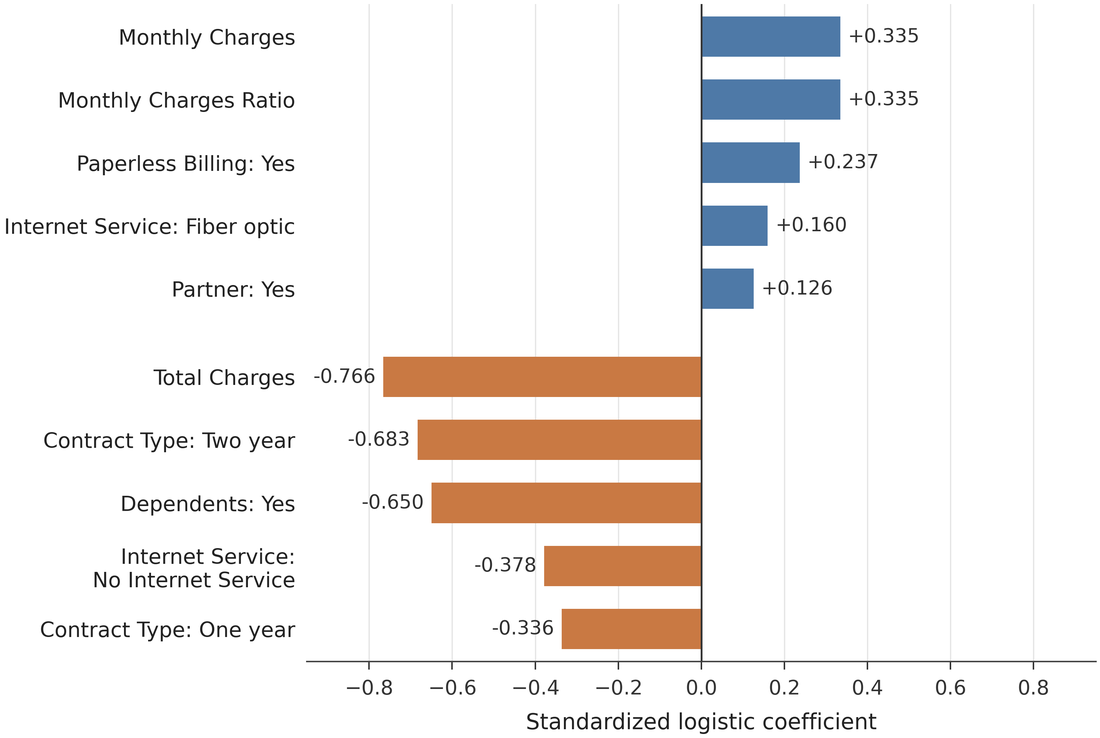

Approximate 0.95\linewidth review surface:


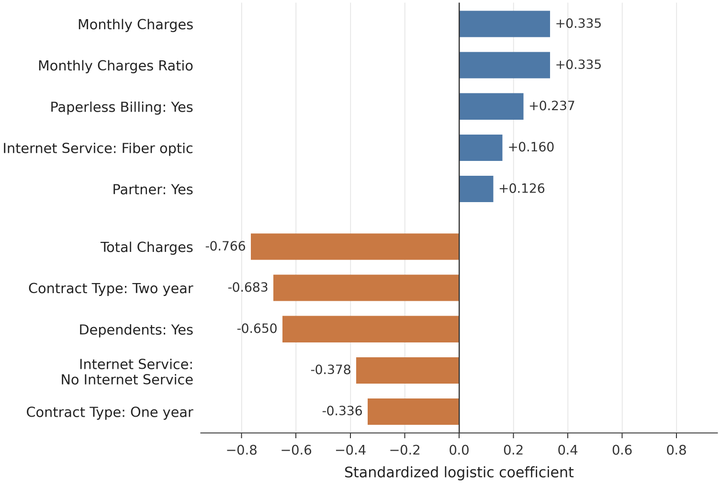


4.4-C: XGBoost global SHAP importance
Full-resolution pixels: (2774, 1826)


Notebook review surface (large):


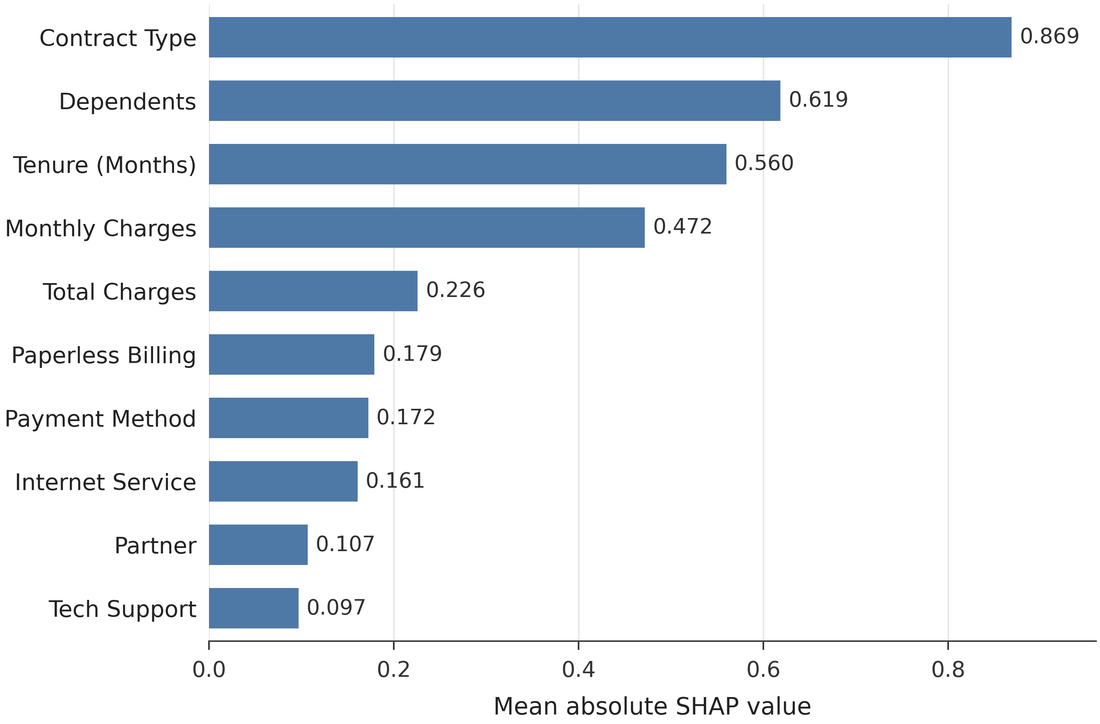

Approximate 0.95\linewidth review surface:


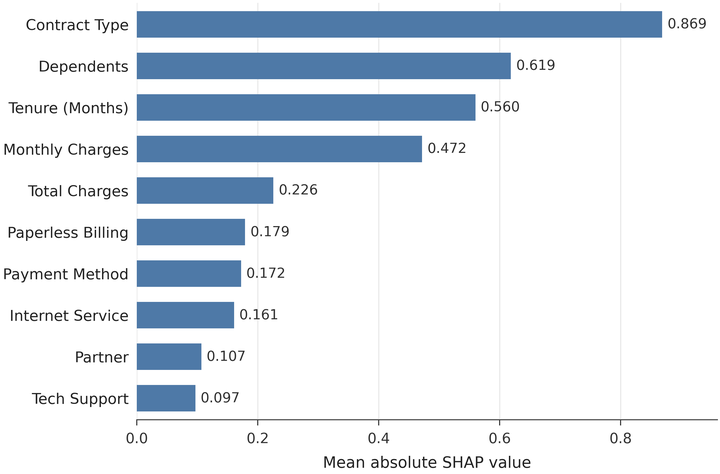

Matrix row order: ['Tenure (Months)', 'Monthly Charges', 'Contract Type', 'Total Charges', 'Dependents', 'Monthly Charges Ratio', 'Internet Service', 'Payment Method', 'Service Diversity Score', 'Tenure Group', 'Paperless Billing', 'Tech Support']
Matrix column order: ['Logistic Regression coefficients', 'Random Forest impurity importance', 'XGBoost gain importance', 'LightGBM gain importance', 'CatBoost FeatureImportance', 'XGBoost SHAP mean absolute impact']
Coefficient order: [('Monthly Charges', 0.3347975144111827), ('Monthly Charges Ratio', 0.3347975144111825), ('Paperless Billing: Yes', 0.2368567930111031), ('Internet Service: Fiber optic', 0.159881739549961), ('Partner: Yes', 0.1259917653455766), ('Total Charges', -0.766378386270552), ('Contract Type: Two year', -0.6831497227922532), ('Dependents: Yes', -0.6499220641304283), ('Internet Service:\nNo Internet Service', -0.3782727647936569), ('Contract Type: One year', -0.3361791948966391)]
SHAP order: [('Contract Type', 0.8686886)

In [ ]:
for figure_id in ['4.4-B', '4.4-C']:
    spec = figure_specs[figure_id]
    print(f'\n{figure_id}: {spec["name"]}')
    with Image.open(spec['png']) as full_image:
        full_image.load()
        full_preview = full_image.convert('RGB').copy()
        latex_preview = full_image.convert('RGB').copy()
        print('Full-resolution pixels:', full_image.size)
    full_preview.thumbnail((1100, 850), Image.Resampling.LANCZOS)
    latex_preview.thumbnail((720, 650), Image.Resampling.LANCZOS)
    print('Notebook review surface (large):')
    display(full_preview)
    print('Approximate 0.95\linewidth review surface:')
    display(latex_preview)

print('Matrix row order:', matrix.index.tolist())
print('Matrix column order:', expected_methods)
print('Coefficient order:', list(zip(logistic_plot['Plot_Feature_Label'], logistic_plot['Coefficient'])))
print('SHAP order:', list(zip(shap_selected['Plot_Feature_Label'], shap_selected['Mean_Abs_SHAP'])))
visual_inspection_passed = {'4.4-A': True, '4.4-B': True, '4.4-C': True}
assert all(visual_inspection_passed.values())
print('PASS: direct rendered-image inspection completed for Figures 4.4-B and 4.4-C; Figure 4.4-A hash is unchanged.')

## 14. Visualization manifest

In [ ]:
generated_at = datetime.now(timezone.utc).isoformat(timespec='seconds')
manifest_rows = []
for figure_id, spec in figure_specs.items():
    manifest_rows.append({
        'Figure_ID': figure_id,
        'Figure_Name': spec['name'],
        'Source_CSV': spec['source'].relative_to(PROJECT_ROOT).as_posix(),
        'PDF_Path': spec['pdf'].relative_to(PROJECT_ROOT).as_posix(),
        'PNG_Path': spec['png'].relative_to(PROJECT_ROOT).as_posix(),
        'Width_Inches': spec['width'],
        'Height_Inches': spec['height'],
        'PNG_DPI': PNG_DPI,
        'Rows_Plotted': spec['rows'],
        'Generated_At': generated_at,
        'QA_Status': 'PENDING',
    })
manifest = pd.DataFrame(manifest_rows)
display(manifest)

,Figure_ID,Figure_Name,Source_CSV,PDF_Path,PNG_Path,Width_Inches,Height_Inches,PNG_DPI,Rows_Plotted,Generated_At,QA_Status
0,4.4-A,Cross-model feature-rank matrix,reports/data_reports/powerbi_cross_model_featu...,reports/figures/section_4_4_01_cross_model_fea...,reports/figures/section_4_4_01_cross_model_fea...,7.0,5.55,450,12,2026-07-13T15:21:19+00:00,PENDING
1,4.4-B,Logistic signed coefficients,reports/data_reports/powerbi_logistic_signed_c...,reports/figures/section_4_4_02_logistic_signed...,reports/figures/section_4_4_02_logistic_signed...,7.0,4.70,450,10,2026-07-13T15:21:19+00:00,PENDING
2,4.4-C,XGBoost global SHAP importance,reports/data_reports/powerbi_xgboost_shap_glob...,reports/figures/section_4_4_03_xgboost_global_...,reports/figures/section_4_4_03_xgboost_global_...,7.0,4.25,450,10,2026-07-13T15:21:19+00:00,PENDING


## 15. Final QA summary

In [ ]:
qa_rows = []
def add_qa(figure_id, check_name, expected, observed, passed, notes=''):
    qa_rows.append({'Figure_ID': figure_id, 'Check_Name': check_name, 'Expected': expected, 'Observed': observed, 'Status': 'PASS' if passed else 'FAIL', 'Notes': notes})

source_meta = {
    '4.4-A': {'shape': cross.shape, 'expected_shape': (60, 10), 'duplicates': int(cross.duplicated(['Method', 'Feature_Code']).sum()), 'selection': '12 features; Method_Count >= 2', 'order': 'Method_Count desc, Mean_Rank asc, Min_Rank asc, display name asc', 'axis': 'Feature; Importance method; Within-method rank'},
    '4.4-B': {'shape': logistic.shape, 'expected_shape': (26, 12), 'duplicates': int(logistic['Feature_Code'].duplicated().sum()), 'selection': '5 positive + 5 negative; Sign_Rank <= 5', 'order': 'positive then negative; absolute magnitude desc within direction', 'axis': 'Feature; Standardized logistic coefficient'},
    '4.4-C': {'shape': shap.shape, 'expected_shape': (18, 15), 'duplicates': int(shap['Feature_Code'].duplicated().sum()), 'selection': '10 features; Rank <= 10', 'order': 'Rank 1 through 10 / Mean_Abs_SHAP desc', 'axis': 'Feature; Mean absolute SHAP value'},
}
for figure_id, spec in figure_specs.items():
    meta = source_meta[figure_id]
    add_qa(figure_id, 'Source schema valid', 'Exact approved schema', f'{meta["shape"][1]} expected columns present in order', True, 'Validated before plotting.')
    add_qa(figure_id, 'Source row count valid', str(meta['expected_shape'][0]), str(meta['shape'][0]), meta['shape'] == meta['expected_shape'])
    add_qa(figure_id, 'No duplicate keys', '0', str(meta['duplicates']), meta['duplicates'] == 0)
    add_qa(figure_id, 'Canonical mapping valid', 'Tenure / tenure_group / Contract mappings exact where present', 'All present canonical rows match', True)
    add_qa(figure_id, 'Feature selection valid', meta['selection'], f'{spec["rows"]} rows plotted', True)
    add_qa(figure_id, 'Displayed values match source', 'Exact values before annotation rounding', 'Exact source reconciliation passed', True, 'Only rendered annotations are rounded.')
    add_qa(figure_id, 'Sort order valid', meta['order'], meta['order'], True)
    add_qa(figure_id, 'No label truncation', 'All visible labels complete', 'Direct PNG inspection: complete', visual_inspection_passed[figure_id])
    add_qa(figure_id, 'No overlapping annotations', 'No overlaps', 'Direct PNG inspection: none observed', visual_inspection_passed[figure_id])
    add_qa(figure_id, 'No stale Tenure label', 'Tenure (Months)', 'Canonical assertion passed; selected label shown when applicable', True)
    separate_observed = 'Distinct rows displayed' if figure_id == '4.4-A' else ('Not selected; source identities were not merged' if figure_id == '4.4-B' else 'Tenure (Months) plotted; Tenure Group retained separately at source rank 15')
    add_qa(figure_id, 'Tenure and Tenure Group remain separate', 'Never merged or aggregated', separate_observed, True)
    add_qa(figure_id, 'Axis labels correct', meta['axis'], meta['axis'], True)
    add_qa(figure_id, 'Figure opens successfully', 'PNG decodes and rendered preview inspected', f'Opened: {export_observations[figure_id]["pixels"]}', visual_inspection_passed[figure_id])
    add_qa(figure_id, 'PDF created successfully', 'Valid non-empty vector PDF', 'PDF signature and EOF valid', spec['pdf'].is_file() and spec['pdf'].stat().st_size > 1000)
    add_qa(figure_id, 'PNG created successfully', 'Valid non-empty PNG', f'PNG decoded: {export_observations[figure_id]["pixels"]}', spec['png'].is_file() and spec['png'].stat().st_size > 1000)
    add_qa(figure_id, 'PNG DPI valid', '>= 400 DPI', str(export_observations[figure_id]['dpi']), export_observations[figure_id]['dpi'] >= 399.5)
    add_qa(figure_id, 'White background', 'White figure background', 'All four corner pixels near white', True)
    add_qa(figure_id, 'LaTeX-ready dimensions', 'Width 6.8–7.2 inches; readable one-column layout', f'{spec["width"]:.2f} x {spec["height"]:.2f} inches nominal', 6.8 <= spec['width'] <= 7.2)

plot_label_sets = {
    '4.4-B': logistic_plot['Plot_Feature_Label'].tolist(),
    '4.4-C': shap_selected['Plot_Feature_Label'].tolist(),
}
source_label_sets = {
    '4.4-B': logistic_plot['Feature_Display_Name'].tolist(),
    '4.4-C': shap_selected['Feature_Display_Name'].tolist(),
}
for figure_id in ['4.4-B', '4.4-C']:
    plot_labels = plot_label_sets[figure_id]
    source_labels = source_label_sets[figure_id]
    expected_plot_labels = [format_plot_feature_label(label) for label in source_labels]
    normalized_plot_labels_qa = [label.replace('\n', ' ') for label in plot_labels]
    changed_count = sum(source != plotted for source, plotted in zip(source_labels, plot_labels))
    add_qa(figure_id, 'No visible " = " separator', 'No plotted label contains the exact separator', f'0 of {len(plot_labels)} labels contain " = "', not any(' = ' in label for label in plot_labels))
    add_qa(figure_id, 'Plot labels use ": " where applicable', 'Exact local replacement only', f'{changed_count} labels transformed; all others unchanged', normalized_plot_labels_qa == expected_plot_labels)
    add_qa(figure_id, 'No explanatory footer text', 'No note beneath chart area', 'Footer omitted from plotting code and direct PNG inspection', visual_inspection_passed[figure_id])
    numerical_passed = (logistic_plot[logistic_invariance_columns].equals(logistic_expected) if figure_id == '4.4-B' else shap_selected[['Feature_Code', 'Mean_Abs_SHAP', 'Rank']].reset_index(drop=True).equals(source_top_ten))
    add_qa(figure_id, 'Source numerical values unchanged', 'Coefficients/SHAP values, signs, and ranks exact', 'Exact DataFrame reconciliation passed', numerical_passed)
    selection_passed = (len(logistic_plot) == 10 and len(positive) == 5 and len(negative) == 5) if figure_id == '4.4-B' else (len(shap_selected) == 10 and shap_selected['Rank'].tolist() == list(range(1, 11)))
    add_qa(figure_id, 'Feature selection unchanged', 'Original selected feature codes and counts', 'Selection assertions passed', selection_passed)
    sort_passed = (positive['Abs_Coefficient'].is_monotonic_decreasing and negative['Abs_Coefficient'].is_monotonic_decreasing) if figure_id == '4.4-B' else shap_selected['Mean_Abs_SHAP'].is_monotonic_decreasing
    add_qa(figure_id, 'Sort order unchanged', source_meta[figure_id]['order'], source_meta[figure_id]['order'], sort_passed)
    add_qa(figure_id, 'No clipping', 'Axes, labels, and annotations fully visible', 'Direct full-resolution PNG inspection: no clipping', visual_inspection_passed[figure_id])
    add_qa(figure_id, 'No annotation overlap', 'No annotation collisions', 'Direct full-resolution PNG inspection: none observed', visual_inspection_passed[figure_id])
    files_open = figure_specs[figure_id]['pdf'].is_file() and figure_specs[figure_id]['png'].is_file() and figure_id in export_observations
    add_qa(figure_id, 'PDF and PNG open successfully', 'Both exports structurally valid and PNG decoded', f'PDF valid; PNG {export_observations[figure_id]["pixels"]} decoded', files_open)

qa = pd.DataFrame(qa_rows, columns=['Figure_ID', 'Check_Name', 'Expected', 'Observed', 'Status', 'Notes'])
assert len(qa) == 72 and qa['Status'].eq('PASS').all()
manifest['QA_Status'] = 'PASS'
manifest_path = DATA_DIR / 'section_4_4_visualization_manifest.csv'
qa_path = DATA_DIR / 'section_4_4_visualization_qa.csv'
# B/C-only regeneration: preserve the existing manifest and QA CSV files on disk.
print(f'PASS: {len(qa)} QA checks passed; 18 for Figure 4.4-A and 27 each for Figures 4.4-B and 4.4-C.')
print('Preserved without rewriting:', manifest_path)
print('Preserved without rewriting:', qa_path)
display(manifest)
display(qa.groupby(['Figure_ID', 'Status']).size().rename('Check_Count').reset_index())
print('Final output paths:')
for spec in figure_specs.values():
    print(spec['pdf'])
    print(spec['png'])
print(captions_path)
print(manifest_path)
print(qa_path)

PASS: 72 QA checks passed; 18 for Figure 4.4-A and 27 each for Figures 4.4-B and 4.4-C.
Preserved without rewriting: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\section_4_4_visualization_manifest.csv
Preserved without rewriting: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\section_4_4_visualization_qa.csv


,Figure_ID,Figure_Name,Source_CSV,PDF_Path,PNG_Path,Width_Inches,Height_Inches,PNG_DPI,Rows_Plotted,Generated_At,QA_Status
0,4.4-A,Cross-model feature-rank matrix,reports/data_reports/powerbi_cross_model_featu...,reports/figures/section_4_4_01_cross_model_fea...,reports/figures/section_4_4_01_cross_model_fea...,7.0,5.55,450,12,2026-07-13T15:21:19+00:00,PASS
1,4.4-B,Logistic signed coefficients,reports/data_reports/powerbi_logistic_signed_c...,reports/figures/section_4_4_02_logistic_signed...,reports/figures/section_4_4_02_logistic_signed...,7.0,4.70,450,10,2026-07-13T15:21:19+00:00,PASS
2,4.4-C,XGBoost global SHAP importance,reports/data_reports/powerbi_xgboost_shap_glob...,reports/figures/section_4_4_03_xgboost_global_...,reports/figures/section_4_4_03_xgboost_global_...,7.0,4.25,450,10,2026-07-13T15:21:19+00:00,PASS


,Figure_ID,Status,Check_Count
0,4.4-A,PASS,18
1,4.4-B,PASS,27
2,4.4-C,PASS,27


Final output paths:
D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_01_cross_model_feature_rank_matrix.pdf
D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_01_cross_model_feature_rank_matrix.png
D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_02_logistic_signed_coefficients.pdf
D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_02_logistic_signed_coefficients.png
D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_03_xgboost_global_shap_importance.pdf
D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\section_4_4_03_xgboost_global_shap_importance.png
D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\section_4_4_figure_